SETUP: 

In [21]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

OUT = Path("docs/eda"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True})

df = pd.read_parquet("data/dataset.parquet")
df["ts"] = pd.to_datetime(df["ts"], utc=True)
df["local"] = df["ts"].dt.tz_convert("Asia/Karachi")   # charts use Karachi time
df["hour_local"] = df["local"].dt.hour
df["month"] = df["local"].dt.strftime("%Y-%m")
labeled = df.dropna(subset=["target_temp_c"])

def save(name):
    plt.tight_layout(); plt.savefig(OUT / f"{name}.png", dpi=130); plt.show()

print(df.shape, "| labeled:", labeled.shape)
print("range:", df["local"].min(), "->", df["local"].max())

(8801, 115) | labeled: (8777, 115)
range: 2025-11-20 05:00:00+05:00 -> 2026-11-21 21:00:00+05:00


OVERVIEW:

In [22]:
base = ["aqi", "pm2_5", "pm10", "o3", "no2", "temp_c", "humidity", "precip_mm",
        "uv_index", "wind_speed_ms", "wind_dir_deg", "pressure_hpa", "cloud_pct"]
print(df[base].describe().round(2).T)
print("\nmissing:", df[base].isna().sum().sum())

                count     mean    std     min      25%      50%      75%  \
aqi            8801.0    88.30  21.05   41.00    74.00    83.00    98.00   
pm2_5          8801.0    28.37  12.28    3.50    19.80    25.50    33.60   
pm10           8801.0    53.60  28.45    3.70    35.60    47.50    64.00   
o3             8801.0    69.75  38.70    0.00    43.00    60.00    92.00   
no2            8801.0    19.63  18.96    0.00     6.90    12.30    26.10   
temp_c         8801.0    26.50   4.63    9.30    23.80    27.40    29.60   
humidity       8801.0    66.11  19.85    7.00    54.00    70.00    82.00   
precip_mm      8801.0     0.01   0.15    0.00     0.00     0.00     0.00   
uv_index       8801.0     1.73   2.39    0.00     0.00     0.05     3.40   
wind_speed_ms  8801.0     3.03   1.24    0.05     2.11     2.97     3.91   
wind_dir_deg   8801.0   220.62  87.48    1.00   219.00   246.00   267.00   
pressure_hpa   8801.0  1009.77   6.37  994.20  1004.40  1009.70  1015.30   
cloud_pct   

PROFILE FUNCTION: (distribution, daily pattern, monthly pattern)

In [23]:
METRICS = {
    "aqi": "AQI (US)", "temp_c": "Temperature (°C)", "humidity": "Humidity (%)",
    "uv_index": "UV index", "wind_speed_ms": "Wind speed (m/s)",
    "precip_mm": "Precipitation (mm/h)",
}

def profile(col, label, logy=False):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    df[col].plot.hist(bins=50, ax=ax[0], logy=logy)
    ax[0].set_title(f"{label}: distribution")
    g = df.groupby("hour_local")[col]
    m = g.mean()
    ax[1].plot(m.index, m.values)
    ax[1].fill_between(m.index, g.quantile(.1), g.quantile(.9), alpha=.25)
    ax[1].set_title("by hour of day (Karachi), mean + 10-90%")
    df.groupby("month")[col].mean().plot(ax=ax[2], marker="o")
    ax[2].set_title("monthly mean"); ax[2].tick_params(axis="x", rotation=60)
    save(f"profile_{col}")
    print(df[col].describe().round(2).to_string())

RUNNING ONE METRIC PER CELL:

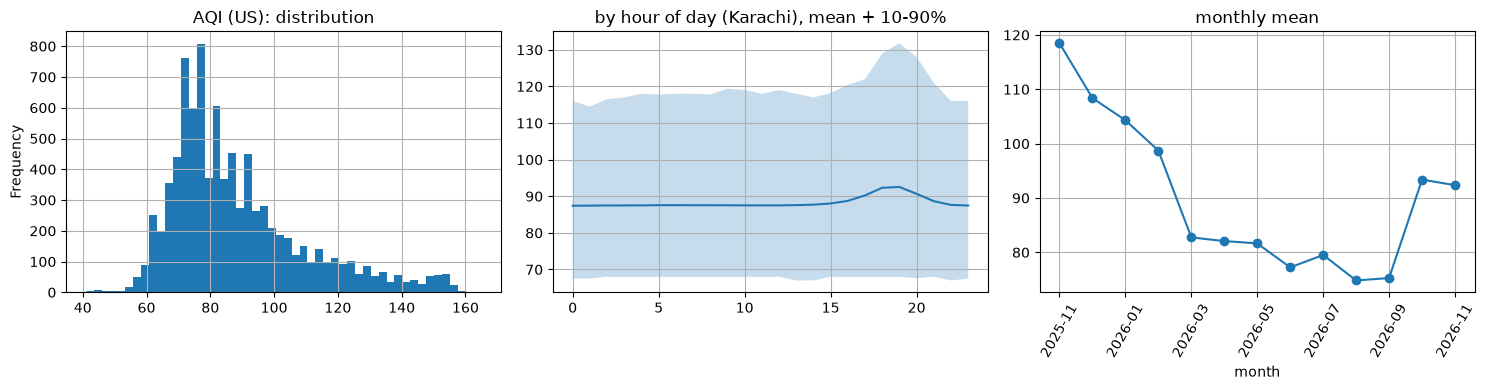

count    8801.00
mean       88.30
std        21.05
min        41.00
25%        74.00
50%        83.00
75%        98.00
max       165.00


In [24]:
profile("aqi", METRICS["aqi"])

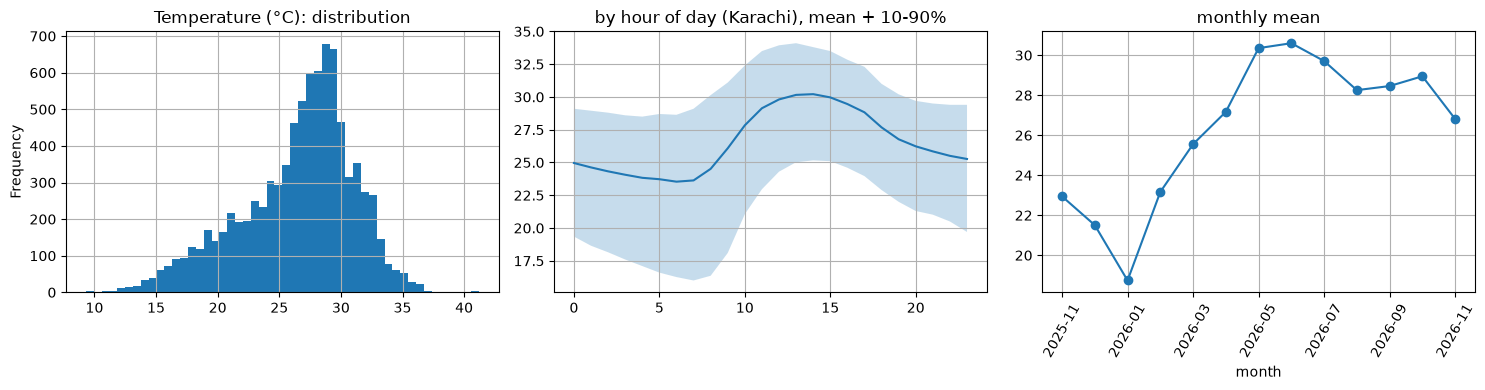

count    8801.00
mean       26.50
std         4.63
min         9.30
25%        23.80
50%        27.40
75%        29.60
max        41.20


In [25]:
profile("temp_c", METRICS["temp_c"])

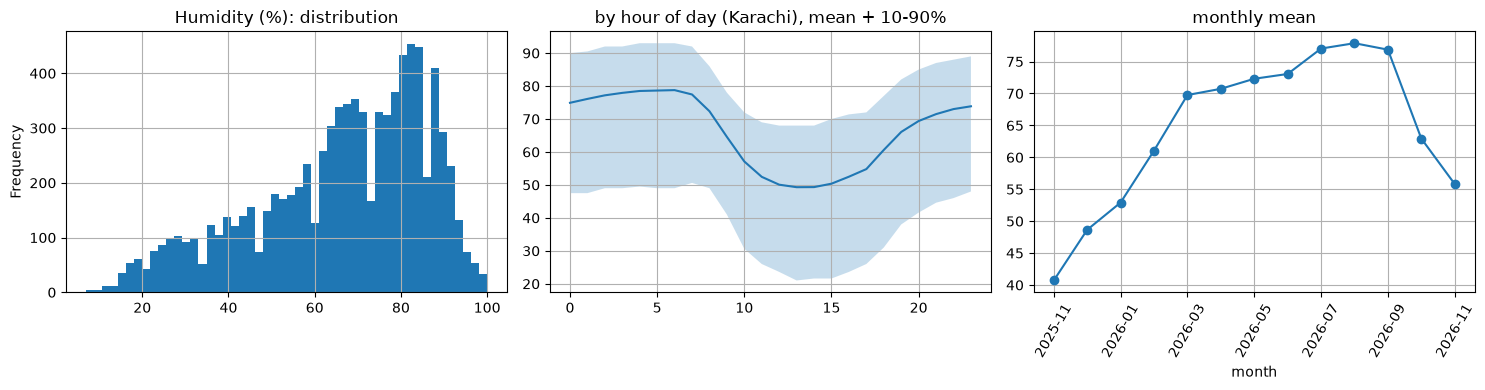

count    8801.00
mean       66.11
std        19.85
min         7.00
25%        54.00
50%        70.00
75%        82.00
max       100.00


In [26]:
profile("humidity", METRICS["humidity"])

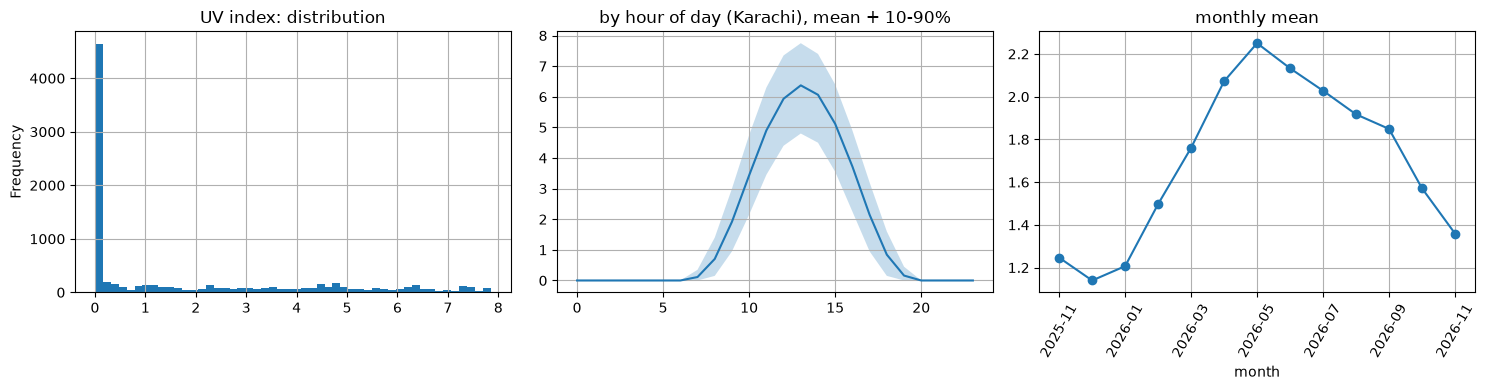

count    8801.00
mean        1.73
std         2.39
min         0.00
25%         0.00
50%         0.05
75%         3.40
max         7.85


In [27]:
profile("uv_index", METRICS["uv_index"])

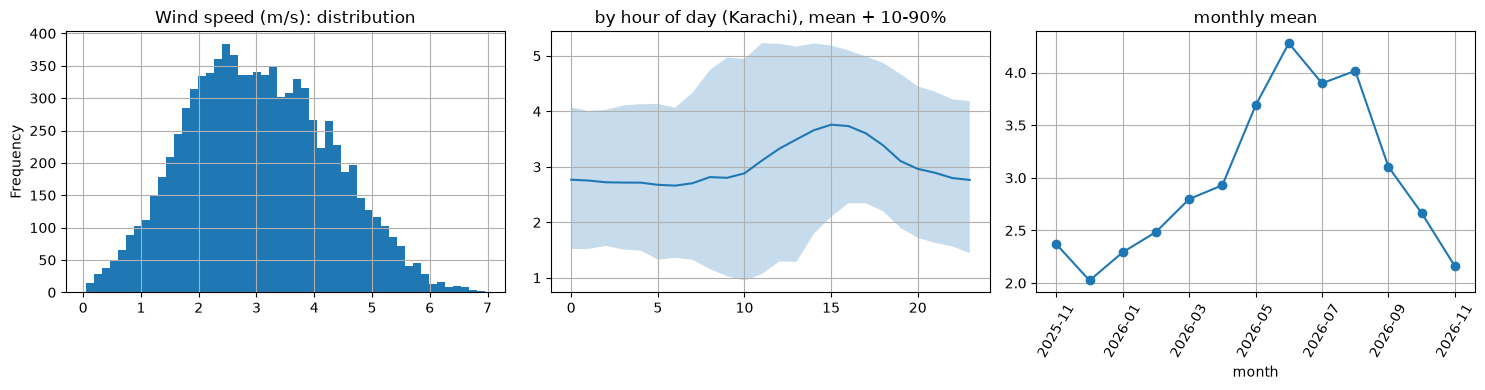

count    8801.00
mean        3.03
std         1.24
min         0.05
25%         2.11
50%         2.97
75%         3.91
max         6.95


In [28]:
profile("wind_speed_ms", METRICS["wind_speed_ms"])

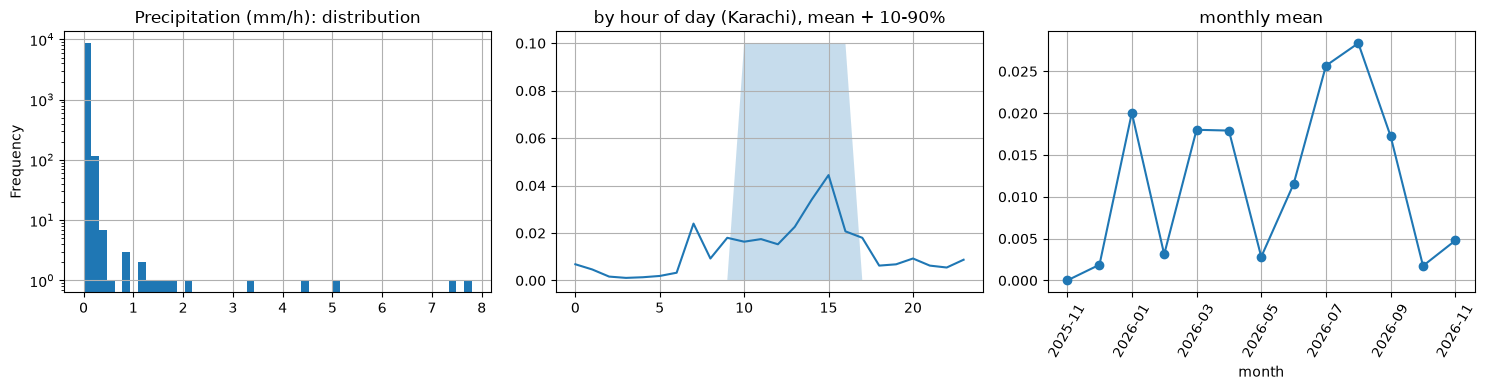

count    8801.00
mean        0.01
std         0.15
min         0.00
25%         0.00
50%         0.00
75%         0.00
max         7.80


In [29]:
profile("precip_mm", METRICS["precip_mm"], logy=True)

RAIN IN DETAIL:

         rain_hours  precip_total_mm
month                               
2025-11           0              0.0
2025-12           3              1.4
2026-01           6             14.9
2026-02          11              2.1
2026-03          14             13.4
2026-04          20             12.9
2026-05          17              2.1
2026-06          69              8.3
2026-07         149             19.1
2026-08         164             21.1
2026-09          82             12.4
2026-10          10              1.3
2026-11           8              2.4


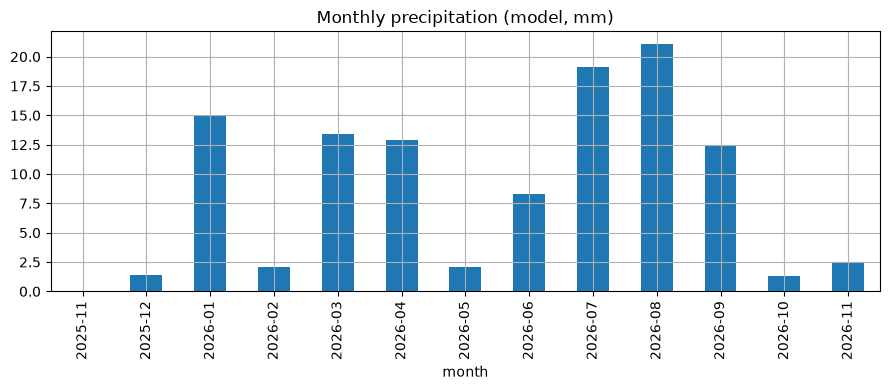

In [30]:
rain = (df["precip_mm"] >= 0.1)
monthly = df.assign(rain=rain).groupby("month").agg(
    rain_hours=("rain", "sum"), precip_total_mm=("precip_mm", "sum"))
print(monthly.round(1))
monthly["precip_total_mm"].plot.bar(title="Monthly precipitation (model, mm)")
save("rain_monthly")

WIND DIRECTION ( a circular variable)

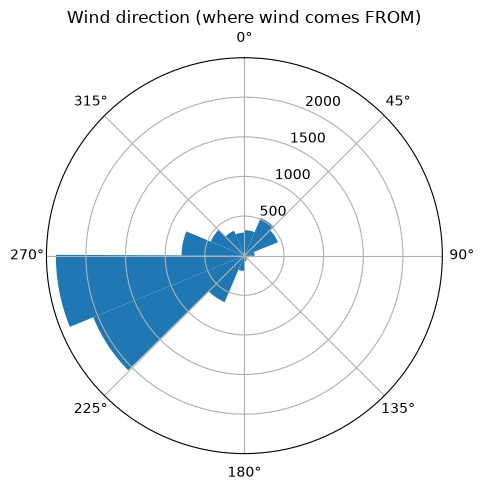

hour_local
0     284.0
1     290.0
2     294.0
3     295.0
4     297.0
5     300.0
6     301.0
7     303.0
8     299.0
9     290.0
10    272.0
11    242.0
12    230.0
13    227.0
14    228.0
15    231.0
16    235.0
17    241.0
18    246.0
19    252.0
20    257.0
21    263.0
22    271.0
23    278.0


In [31]:
fig = plt.figure(figsize=(5, 5)); ax = plt.subplot(111, projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.hist(np.deg2rad(df["wind_dir_deg"]), bins=16)
ax.set_title("Wind direction (where wind comes FROM)")
save("wind_rose")

# circular mean direction by hour: does the sea breeze show up?
h = df.groupby("hour_local").agg(s=("wind_sin", "mean"), c=("wind_cos", "mean"))
h["dir_deg"] = np.degrees(np.arctan2(h["s"], h["c"])) % 360
print(h["dir_deg"].round(0).to_string())

UV AND AQI SANITY CHECKS ( the doubts I flagged):

In [32]:
daily = df.set_index("local").resample("D").agg(uv_max=("uv_index", "max"),
                                                aqi_max=("aqi", "max"))
print(daily.groupby(daily.index.strftime("%Y-%m")).agg(["max", "mean"]).round(1))
print("\nAQI percentiles:", df["aqi"].quantile([.5, .9, .99]).round(0).to_dict())
print("share of hours AQI > 100:", round((df["aqi"] > 100).mean(), 3))
print("share of hours AQI > 150:", round((df["aqi"] > 150).mean(), 3))

        uv_max      aqi_max       
           max mean     max   mean
local                             
2025-11    5.2  5.0   157.0  132.2
2025-12    5.0  4.7   154.0  119.7
2026-01    5.4  4.9   156.0  116.7
2026-02    6.5  5.9   165.0  112.3
2026-03    7.4  6.7   147.0   94.9
2026-04    7.8  7.4   161.0  100.1
2026-05    7.8  7.8   133.0   88.4
2026-06    7.8  7.3    99.0   80.9
2026-07    7.8  7.2   109.0   82.5
2026-08    7.8  7.1    94.0   77.3
2026-09    7.4  6.9   144.0   81.8
2026-10    6.8  6.1   158.0  103.9
2026-11    5.8  5.4   143.0  104.5

AQI percentiles: {0.5: 83.0, 0.9: 120.0, 0.99: 153.0}
share of hours AQI > 100: 0.219
share of hours AQI > 150: 0.017


CORRELATIONS:

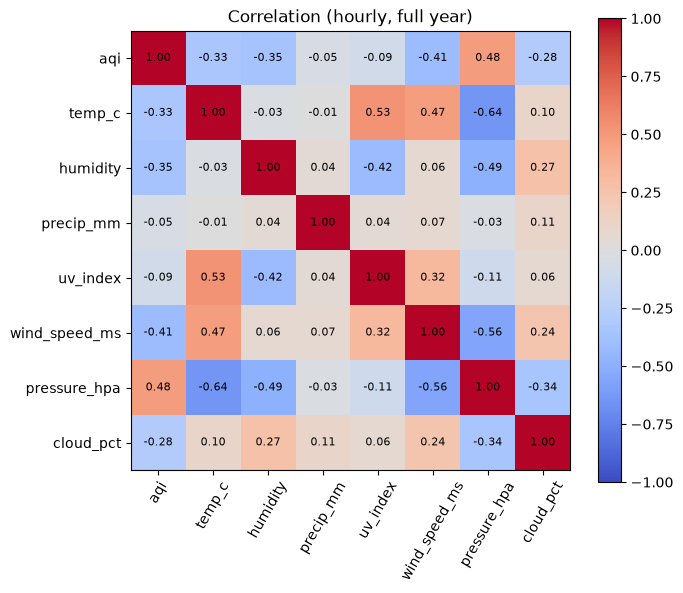

In [33]:
cols = ["aqi", "temp_c", "humidity", "precip_mm", "uv_index",
        "wind_speed_ms", "pressure_hpa", "cloud_pct"]
corr = df[cols].corr()
plt.figure(figsize=(7, 6)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(cols)), cols, rotation=60); plt.yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(); plt.title("Correlation (hourly, full year)"); plt.grid(False)
save("correlations")

AUTOCORRECTION (Why the baseline is strong)

In [34]:
for c in ["aqi", "temp_c", "humidity", "uv_index", "wind_speed_ms", "precip_mm"]:
    print(f"{c:15s} lag1={df[c].autocorr(1):.2f}  lag24={df[c].autocorr(24):.2f}  "
          f"lag168={df[c].autocorr(168):.2f}")

aqi             lag1=0.99  lag24=0.71  lag168=0.33
temp_c          lag1=0.98  lag24=0.97  lag168=0.90
humidity        lag1=0.97  lag24=0.84  lag168=0.59
uv_index        lag1=0.94  lag24=0.98  lag168=0.98
wind_speed_ms   lag1=0.95  lag24=0.71  lag168=0.50
precip_mm       lag1=0.32  lag24=0.01  lag168=0.01


THE NAIVE BASELINE (the bar to beat):

In [35]:
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             precision_score, recall_score, f1_score)

split = int(len(labeled) * 0.8)            # time-based split, no shuffling
sets = {"full year": labeled, "last 20% (validation-like)": labeled.iloc[split:]}

pairs = {"aqi": "target_aqi", "temp_c": "target_temp_c", "humidity": "target_humidity",
         "uv_index": "target_uv_index", "wind_speed_ms": "target_wind_speed_ms",
         "precip_mm": "target_precip_mm"}

rows = []
for name, d in sets.items():
    for feat, tgt in pairs.items():
        y, p = d[tgt], d[feat]
        rows.append({"set": name, "metric": feat,
                     "RMSE": mean_squared_error(y, p) ** 0.5,
                     "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)})
    # wind direction: angular error in degrees
    a_now = np.degrees(np.arctan2(d["wind_sin"], d["wind_cos"]))
    a_tgt = np.degrees(np.arctan2(d["target_wind_sin"], d["target_wind_cos"]))
    err = np.abs((a_now - a_tgt + 180) % 360 - 180)
    rows.append({"set": name, "metric": "wind_direction (deg error)",
                 "RMSE": np.sqrt((err ** 2).mean()), "MAE": err.mean(), "R2": np.nan})

res = pd.DataFrame(rows).round(3)
print(res.to_string(index=False))
res.to_csv(OUT / "baseline_scores.csv", index=False)

                       set                     metric   RMSE    MAE     R2
                 full year                        aqi 16.084 10.983  0.416
                 full year                     temp_c  1.151  0.762  0.938
                 full year                   humidity 11.178  7.307  0.683
                 full year                   uv_index  0.446  0.125  0.965
                 full year              wind_speed_ms  0.950  0.714  0.410
                 full year                  precip_mm  0.212  0.021 -0.975
                 full year wind_direction (deg error) 40.164 24.876    NaN
last 20% (validation-like)                        aqi 14.557 10.753  0.315
last 20% (validation-like)                     temp_c  1.085  0.797  0.890
last 20% (validation-like)                   humidity 12.249  8.354  0.682
last 20% (validation-like)                   uv_index  0.352  0.078  0.975
last 20% (validation-like)              wind_speed_ms  0.852  0.644  0.295
last 20% (validation-like

THE RAIN BASELINE (Classification, Never use accuracy):)

In [36]:
for name, d in sets.items():
    y = d["target_rain"].astype(int); p = (d["precip_mm"] >= 0.1).astype(int)
    print(f"[{name}] rain rate={y.mean():.3f} | "
          f"always-'no rain' accuracy={(1 - y.mean()):.3f} | "
          f"naive precision={precision_score(y, p, zero_division=0):.2f} "
          f"recall={recall_score(y, p, zero_division=0):.2f} "
          f"F1={f1_score(y, p, zero_division=0):.2f}")

[full year] rain rate=0.063 | always-'no rain' accuracy=0.937 | naive precision=0.35 recall=0.35 F1=0.35
[last 20% (validation-like)] rain rate=0.021 | always-'no rain' accuracy=0.979 | naive precision=0.24 recall=0.24 F1=0.24


UV ONLY MATTERS IN DAYTIME:


In [37]:
day = labeled[labeled["target_uv_index"] > 0]
print("daytime rows:", len(day), "of", len(labeled))
print("UV naive MAE, daytime only:",
      round(mean_absolute_error(day["target_uv_index"], day["uv_index"]), 3))

daytime rows: 4471 of 8777
UV naive MAE, daytime only: 0.246
